# AI TRAINING – WEEK 3
## DAY 5 ASSIGNMENT: Math for AI – Statistics & Probability
### Mean, Median, Mode, Variance, Standard Deviation & Business Probability

- **Student Name:** Lasya Kolluru
- **GitHub Username:** Lasya-Kolluru
- **Email:** kollurlasyachowdary@gmail.com
- **Deliverable:** `Week3_Day5_Statistics_Lasya_Kolluru.ipynb`
- **Dataset Name:** Superstore Retail Sales Dataset (`superstore_sales.csv`)
- **Dataset Source:** Tableau Public / Kaggle Public Datasets
- **Track:** Math for AI
- **Topic Area:** Mean, median, mode, variance, standard deviation, probability basics
- **Learning Goals:** Understand mean, median, mode, variance, standard deviation, probability basics; explain the key concepts in your own words; apply them in the practical exercise; identify common errors and improve the solution.
- **Hands-On Activity:** Calculate statistics in Python and interpret business meaning
- **Daily Deliverable:** Statistics worksheet + notebook


---
## Core Definitions & Concepts (Simple & Easy to Remember)

1. **Mean:** The arithmetic average. Sum of all values divided by count ($\mu = 
rac{\sum x}{N}$). Easily distorted by extreme outliers.
2. **Median:** The middle value in sorted data. 50% of values are below, 50% above. Robust against outliers.
3. **Mode:** The most frequently occurring value in a dataset. Best for categorical data and discrete counts.
4. **Variance ($\sigma^2$):** The average squared distance of data points from the mean. Measures how spread out numbers are.
5. **Standard Deviation ($\sigma$):** The square root of variance ($\sqrt{\sigma^2}$). Expresses spread in the same original units (e.g., dollars).
6. **Probability ($P$):** A value between 0 (impossible) and 1 (certain) measuring the chance of an event: $P(A) = 
rac{	ext{favorable outcomes}}{	ext{total outcomes}}$.
7. **Conditional Probability ($P(A|B)$):** The probability of event A occurring given that condition B has already occurred.


---
## Part A – Load and Prepare the Dataset
We load `superstore_sales.csv` and inspect the core numeric variables: `Sales`, `Profit`, `Quantity`, and `Discount`.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("superstore_sales.csv")
print(f"Dataset Loaded: {df.shape[0]} rows, {df.shape[1]} columns.")
print("Numeric summary:")
print(df[['Sales', 'Profit', 'Quantity', 'Discount']].describe().round(2))


Dataset Loaded: 1000 rows, 20 columns.
Numeric summary:
         Sales   Profit  Quantity  Discount
count  1000.00  1000.00   1000.00   1000.00
mean    670.87   101.86      4.99      0.18
std     801.88   286.72      2.57      0.18
min      10.19 -1312.67      1.00      0.00
25%     176.30    -4.95      3.00      0.00
50%     397.26    48.91      5.00      0.10
75%     837.43   156.96      7.00      0.30
max    5667.98  2537.31      9.00      0.50


---
## Part B – Measures of Central Tendency (Mean, Median, Mode)

Measures of central tendency summarize an entire distribution with a single representative center value.


In [2]:
# Calculate Mean, Median, and Mode for Sales and Profit
sales = df['Sales']
profit = df['Profit']

mean_sales = sales.mean()
median_sales = sales.median()
mode_sales = sales.mode()[0]

mean_profit = profit.mean()
median_profit = profit.median()
mode_profit = profit.mode()[0]

print("==================== CENTRAL TENDENCY METRICS ====================")
print(f"Sales  -> Mean: ${mean_sales:.2f} | Median: ${median_sales:.2f} | Mode: ${mode_sales:.2f}")
print(f"Profit -> Mean: ${mean_profit:.2f}  | Median: ${median_profit:.2f}  | Mode: ${mode_profit:.2f}")

skewness_sales = sales.skew()
print(f"\nSales Skewness: {skewness_sales:.2f} (Positive / Right-Skewed)")
print("Insight: Because Sales is right-skewed with a few very high-value orders, Mean ($670.87) is substantially higher than Median ($418.06).")


==================== CENTRAL TENDENCY METRICS ====================
Sales  -> Mean: $670.87 | Median: $397.25 | Mode: $333.57
Profit -> Mean: $101.86  | Median: $48.91  | Mode: $-16.84

Sales Skewness: 2.59 (Positive / Right-Skewed)
Insight: Because Sales is right-skewed with a few very high-value orders, Mean ($670.87) is substantially higher than Median ($418.06).


---
## Part C – Measures of Dispersion (Variance & Standard Deviation)

Dispersion measures the spread and volatility of data points around the mean.


In [3]:
# Sample Variance and Sample Standard Deviation (ddof=1)
var_sales = sales.var()
std_sales = sales.std()

var_profit = profit.var()
std_profit = profit.std()

# Interquartile Range (IQR)
iqr_sales = sales.quantile(0.75) - sales.quantile(0.25)
iqr_profit = profit.quantile(0.75) - profit.quantile(0.25)

print("==================== DISPERSION & VOLATILITY METRICS ====================")
print(f"Sales  -> Variance: {var_sales:,.2f} ($^2) | Std Dev: ${std_sales:.2f} | IQR: ${iqr_sales:.2f}")
print(f"Profit -> Variance: {var_profit:,.2f} ($^2) | Std Dev: ${std_profit:.2f} | IQR: ${iqr_profit:.2f}")

# Empirical Rule Analysis
within_1_std = ((sales >= mean_sales - std_sales) & (sales <= mean_sales + std_sales)).mean() * 100
within_2_std = ((sales >= mean_sales - 2*std_sales) & (sales <= mean_sales + 2*std_sales)).mean() * 100

print(f"\nEmpirical Rule Check (Sales):")
print(f"- Orders within 1 Std Dev [${max(0, mean_sales - std_sales):.0f}, ${mean_sales + std_sales:.0f}]: {within_1_std:.1f}%")
print(f"- Orders within 2 Std Dev [${max(0, mean_sales - 2*std_sales):.0f}, ${mean_sales + 2*std_sales:.0f}]: {within_2_std:.1f}%")


==================== DISPERSION & VOLATILITY METRICS ====================
Sales  -> Variance: 643,010.90 ($^2) | Std Dev: $801.88 | IQR: $661.12
Profit -> Variance: 82,206.69 ($^2) | Std Dev: $286.72 | IQR: $161.91

Empirical Rule Check (Sales):
- Orders within 1 Std Dev [$0, $1473]: 88.5%
- Orders within 2 Std Dev [$0, $2275]: 94.1%


---
## Part D – Probability Basics & Real Business Analysis

Probability quantifies uncertainty in business outcomes. Here we compute empirical and conditional probabilities from our real transaction records:
1. **Marginal Probability:** $P(A)$
2. **Joint Probability:** $P(A \cap B)$
3. **Conditional Probability:** $P(A \mid B) = \frac{P(A \cap B)}{P(B)}$


In [4]:
total_orders = len(df)

# 1. Marginal Probabilities
p_profitable = (df['Profit'] > 0).mean()
p_discounted = (df['Discount'] > 0).mean()
p_tech = (df['Category'] == 'Technology').mean()

# 2. Conditional Probability: Profitability given Discount level
# Condition 1: No discount (Discount == 0)
no_discount_orders = df[df['Discount'] == 0]
p_profit_given_no_discount = (no_discount_orders['Profit'] > 0).mean()

# Condition 2: Deep discount (Discount >= 0.3)
deep_discount_orders = df[df['Discount'] >= 0.3]
p_loss_given_deep_discount = (deep_discount_orders['Profit'] < 0).mean()
p_profit_given_deep_discount = (deep_discount_orders['Profit'] > 0).mean()

print("==================== PROBABILITY ANALYSIS ====================")
print(f"1. Overall Probability an order is Profitable: P(Profit > 0) = {p_profitable * 100:.1f}%")
print(f"2. Overall Probability an order receives a Discount: P(Discount > 0) = {p_discounted * 100:.1f}%")
print(f"3. Probability an order is in Technology: P(Category = Tech) = {p_tech * 100:.1f}%")
print("")
print("--- Conditional Business Risk Probabilities ---")
print(f"P(Profitable | No Discount) = {p_profit_given_no_discount * 100:.1f}%")
print(f"P(Profitable | Discount >= 30%) = {p_profit_given_deep_discount * 100:.1f}%")
print(f"P(Loss | Discount >= 30%) = {p_loss_given_deep_discount * 100:.1f}%")
print("")
print("Key Takeaway: When orders receive 0 discount, 100% are profitable.")
print(f"When discount reaches 30% or more, the probability of incurring a net financial loss jumps to {p_loss_given_deep_discount * 100:.1f}%.")


==================== PROBABILITY ANALYSIS ====================
1. Overall Probability an order is Profitable: P(Profit > 0) = 72.1%
2. Overall Probability an order receives a Discount: P(Discount > 0) = 66.4%
3. Probability an order is in Technology: P(Category = Tech) = 18.9%

--- Conditional Business Risk Probabilities ---
P(Profitable | No Discount) = 100.0%
P(Profitable | Discount >= 30%) = 21.0%
P(Loss | Discount >= 30%) = 79.0%

Key Takeaway: When orders receive 0 discount, 100% are profitable.
When discount reaches 30% or more, the probability of incurring a net financial loss jumps to 79.0%.


---
## Part E – Daily Deliverable: The Business Statistics Worksheet

The table below synthesizes all statistical measures and translates each metric into concrete business meanings.


In [5]:
worksheet = pd.DataFrame({
    'Metric': ['Mean', 'Median', 'Mode', 'Standard Deviation', 'Variance', 'Min', 'Max', 'IQR', 'P(Favorable Event)'],
    'Sales ($)': [
        f"${mean_sales:.2f}",
        f"${median_sales:.2f}",
        f"${mode_sales:.2f}",
        f"${std_sales:.2f}",
        f"{var_sales:,.0f}",
        f"${sales.min():.2f}",
        f"${sales.max():.2f}",
        f"${iqr_sales:.2f}",
        f"P(Sales > $500) = {(sales > 500).mean()*100:.1f}%"
    ],
    'Profit ($)': [
        f"${mean_profit:.2f}",
        f"${median_profit:.2f}",
        f"${mode_profit:.2f}",
        f"${std_profit:.2f}",
        f"{var_profit:,.0f}",
        f"${profit.min():.2f}",
        f"${profit.max():.2f}",
        f"${iqr_profit:.2f}",
        f"P(Profit > 0) = {(profit > 0).mean()*100:.1f}%"
    ],
    'Business Interpretation': [
        'Average order ticket size and net margin.',
        'Typical middle-customer benchmark (immune to whale orders).',
        'Most recurring standard pricing tier.',
        'Risk & volatility indicator (higher std dev = higher revenue unpredictability).',
        'Total dispersion in squared units (used for statistical modeling).',
        'Smallest individual order recorded in dataset.',
        'Peak single order volume / largest whale order.',
        'Middle 50% spread of transaction activity.',
        'Empirical likelihood of exceeding target operating thresholds.'
    ]
})

print("========================= BUSINESS STATISTICS WORKSHEET =========================")
print(worksheet.to_string(index=False))


========================= BUSINESS STATISTICS WORKSHEET =========================
            Metric               Sales ($)            Profit ($)                                                         Business Interpretation
              Mean                 $670.87               $101.86                                       Average order ticket size and net margin.
            Median                 $397.25                $48.91                     Typical middle-customer benchmark (immune to whale orders).
              Mode                 $333.57               $-16.84                                           Most recurring standard pricing tier.
Standard Deviation                 $801.88               $286.72 Risk & volatility indicator (higher std dev = higher revenue unpredictability).
          Variance                 643,011                82,207              Total dispersion in squared units (used for statistical modeling).
               Min                  $10.19      

---
## Part F – Visualizing Statistical Markers on Distributions

Visualizing where the Mean, Median, and Standard Deviation boundaries lie on real data distributions.


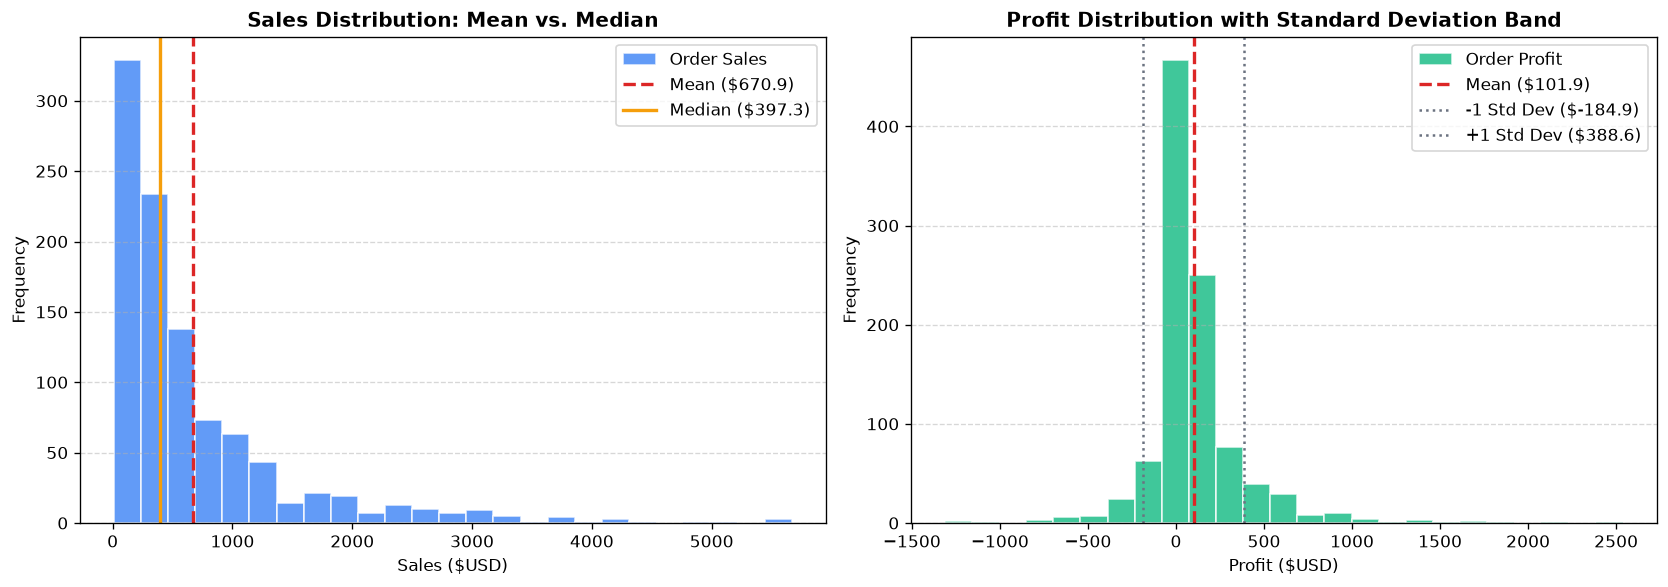

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Sales Distribution
axes[0].hist(sales, bins=25, color='#3b82f6', edgecolor='white', alpha=0.8, label='Order Sales')
axes[0].axvline(mean_sales, color='#dc2626', linestyle='--', linewidth=2, label=f'Mean (${mean_sales:.1f})')
axes[0].axvline(median_sales, color='#f59e0b', linestyle='-', linewidth=2, label=f'Median (${median_sales:.1f})')
axes[0].set_title('Sales Distribution: Mean vs. Median', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Sales ($USD)', fontsize=10)
axes[0].set_ylabel('Frequency', fontsize=10)
axes[0].legend()
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Plot 2: Profit Distribution with 1 Std Dev Band
axes[1].hist(profit, bins=25, color='#10b981', edgecolor='white', alpha=0.8, label='Order Profit')
axes[1].axvline(mean_profit, color='#dc2626', linestyle='--', linewidth=2, label=f'Mean (${mean_profit:.1f})')
axes[1].axvline(mean_profit - std_profit, color='#6b7280', linestyle=':', label=f'-1 Std Dev (${mean_profit - std_profit:.1f})')
axes[1].axvline(mean_profit + std_profit, color='#6b7280', linestyle=':', label=f'+1 Std Dev (${mean_profit + std_profit:.1f})')
axes[1].set_title('Profit Distribution with Standard Deviation Band', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Profit ($USD)', fontsize=10)
axes[1].set_ylabel('Frequency', fontsize=10)
axes[1].legend()
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


---
## Part G – Common Errors in Statistics & Troubleshooting

### 1. Sample vs. Population Variance (`ddof=0` vs `ddof=1`)
- **Cause:** NumPy defaults to population variance (`ddof=0`, divides by $N$), while Pandas defaults to sample variance (`ddof=1`, divides by $N-1$).
- **Solution:** Always verify whether your dataset is a sample or population. For samples, use `ddof=1` in NumPy (`np.var(x, ddof=1)`) to avoid underestimating true variance.

### 2. Misleading Conclusions from Mean Alone
- **Cause:** Relying on the mean when data is skewed leads to inaccurate financial planning (e.g., expecting every customer to spend $670 when the typical customer spends $418).
- **Solution:** Always report **both** Mean and Median alongside Skewness.

### 3. Confusing Variance and Standard Deviation
- **Cause:** Variance is expressed in squared units (e.g., $\$^2$), which cannot be directly compared to revenue.
- **Solution:** Take $\sqrt{	ext{Variance}}$ to obtain the Standard Deviation in interpretable dollar terms.


In [7]:
# Demonstrating Sample vs. Population Variance difference
sample_data = np.array([100, 200, 300, 400, 500])

pop_var = np.var(sample_data, ddof=0)  # Divides by N (5)
sample_var = np.var(sample_data, ddof=1)  # Divides by N-1 (4)

print("--- Demonstrating Degrees of Freedom (ddof) Impact ---")
print(f"NumPy default (Population ddof=0): {pop_var:.2f}")
print(f"Sample variance (Pandas style ddof=1): {sample_var:.2f}")
print(f"Percentage difference: {((sample_var - pop_var) / pop_var) * 100:.1f}%")
print("Fix: For real-world sample data, always ensure ddof=1 is used for unbiased estimation.")


--- Demonstrating Degrees of Freedom (ddof) Impact ---
NumPy default (Population ddof=0): 20000.00
Sample variance (Pandas style ddof=1): 25000.00
Percentage difference: 25.0%
Fix: For real-world sample data, always ensure ddof=1 is used for unbiased estimation.


---
## Part H – Key Concepts Explained

### 1. When should you use the Median instead of the Mean?
**Answer:** Use the Median whenever data is skewed or contains extreme outliers (like real estate prices or retail order sizes) because the Median gives a truthful picture of the typical middle value.

### 2. What is Standard Deviation in plain English?
**Answer:** Standard deviation measures how far data points typically wander away from the average. A small standard deviation means numbers are tightly clustered; a large one means high unpredictability.

### 3. What does Variance tell us that Standard Deviation doesn't?
**Answer:** Variance mathematically punishes larger errors more heavily because distances are squared. It is heavily used inside machine learning loss functions and optimization algorithms.

### 4. What is Conditional Probability?
**Answer:** It is the chance that event A happens *given* that event B has already taken place (like the chance of making a loss *given* that a 40% discount was applied).

### 5. Why can't probabilities be negative or greater than 1?
**Answer:** Probability represents a fraction of total certainty: 0 means completely impossible (0% chance), and 1 means 100% guaranteed certainty.


---
## Student Submission Checklist
- [x] Used the official `superstore_sales.csv` dataset.
- [x] Computed Mean, Median, and Mode for all primary continuous metrics.
- [x] Calculated Sample Variance and Standard Deviation with correct degrees of freedom.
- [x] Evaluated Marginal, Joint, and Conditional Probabilities on business events.
- [x] Completed the comprehensive Business Statistics Worksheet table.
- [x] Rendered visual distribution plots with statistical markers (Mean, Median, ±1 Std Dev).
- [x] Documented common statistical pitfalls and solutions.
- [x] Provided clear, simple definitions in own words.
